# 01 · Data exploration: YouTube ad clicks

**Goal:** understand what drives clicks before we build a linear regression model.

Steps in this notebook:
1. Load the raw data and check its shape, types and quality
2. Clean it (duplicates, missing values, impossible rows)
3. Look at the target (`clicks`) and how each feature relates to it
4. Engineer features and check which ones are linear with the target
5. Save a clean, model-ready dataset

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.append(str(ROOT / 'src'))
from features import clean, add_features, NUMERIC, CATEGORICAL, TARGET

pd.set_option('display.max_columns', 30)

## 1. Load the raw data
Generate it first with `python src/generate_data.py` if `data/youtube_ads.csv` doesn't exist.

In [2]:
raw = pd.read_csv(ROOT / 'data' / 'youtube_ads.csv')
print(raw.shape)
raw.head()

(20100, 15)


,ad_id,category,device,ad_format,age_group,hour,day_of_week,is_weekend,ad_length_sec,daily_budget_usd,impressions,channel_subscribers,video_watch_pct,thumbnail_quality,clicks
0,AD000000,Gaming,Desktop,Skippable,45-54,11,6,1,12,347.81,105310,353698.0,31.2,4,983
1,AD000001,Travel,Desktop,Skippable,25-34,5,4,0,73,52.22,13474,142244.0,53.2,3,104
2,AD000002,Food,Mobile,In-feed,35-44,21,0,0,23,231.89,75140,340132.0,34.7,3,1165
3,AD000003,Education,Mobile,Skippable,18-24,5,0,0,20,149.54,23785,43725.0,40.6,4,122
4,AD000004,Education,Mobile,Skippable,35-44,2,4,0,35,987.04,308494,28952.0,86.0,1,1785


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 20100 entries, 0 to 20099
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ad_id                20100 non-null  str    
 1   category             20100 non-null  str    
 2   device               20100 non-null  str    
 3   ad_format            20100 non-null  str    
 4   age_group            20100 non-null  str    
 5   hour                 20100 non-null  int64  
 6   day_of_week          20100 non-null  int64  
 7   is_weekend           20100 non-null  int64  
 8   ad_length_sec        20100 non-null  int64  
 9   daily_budget_usd     20100 non-null  float64
 10  impressions          20100 non-null  int64  
 11  channel_subscribers  19917 non-null  float64
 12  video_watch_pct      19893 non-null  float64
 13  thumbnail_quality    20100 non-null  int64  
 14  clicks               20100 non-null  int64  
dtypes: float64(3), int64(7), str(5)
memory usage: 2

In [4]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
hour,20100.0,11.52,6.88,0.00,6.00,12.00,17.00,23.00
day_of_week,20100.0,2.99,2.00,0.00,1.00,3.00,5.00,6.00
is_weekend,20100.0,0.28,0.45,0.00,0.00,0.00,1.00,1.00
ad_length_sec,20100.0,56.06,36.57,6.00,22.00,55.00,88.00,120.00
daily_budget_usd,20100.0,205.30,198.93,6.96,86.14,147.51,253.81,3774.67
impressions,20100.0,52968.20,54471.90,1962.00,20896.75,36606.50,65178.25,915699.00
channel_subscribers,19917.0,184610.87,507193.09,208.00,21463.00,60023.00,165906.00,23404124.00
video_watch_pct,19893.0,55.30,17.75,5.00,43.20,55.10,67.40,100.00
thumbnail_quality,20100.0,3.00,1.42,1.00,2.00,3.00,4.00,5.00
clicks,20100.0,520.52,652.05,6.00,164.00,322.00,627.00,11264.00


## 2. Data quality and cleaning

In [5]:
print('Duplicate ad_ids:', raw['ad_id'].duplicated().sum())
print('Missing values per column:')
raw.isna().sum()[lambda s: s > 0]

Duplicate ad_ids: 100
Missing values per column:


channel_subscribers    183
video_watch_pct        207
dtype: int64

In [6]:
df = clean(raw)
print(f'{len(raw):,} rows -> {len(df):,} rows after cleaning')

20,100 rows -> 20,000 rows after cleaning


Missing values in `video_watch_pct` and `channel_subscribers` are filled later with the median, inside the model pipeline, so the same rule applies to new data at prediction time.

## 3. The target: clicks

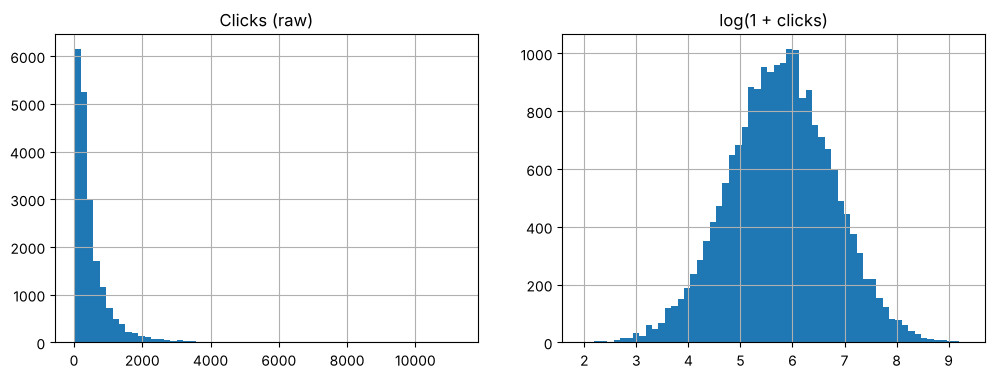

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df['clicks'].hist(bins=60, ax=ax[0]); ax[0].set_title('Clicks (raw)')
np.log1p(df['clicks']).hist(bins=60, ax=ax[1]); ax[1].set_title('log(1 + clicks)')
plt.show()

Clicks are heavily right-skewed: a few big-budget ads get huge numbers. Linear regression assumes errors are roughly symmetric with constant spread, so we'll compare predicting raw clicks against predicting `log(1 + clicks)` in Step 2.

## 4. What drives clicks?
### Impressions and budget

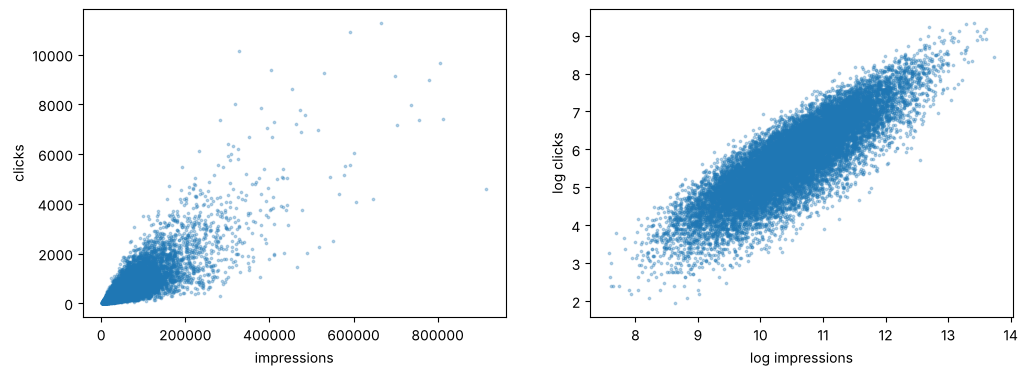

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(df['impressions'], df['clicks'], s=3, alpha=0.3); ax[0].set_xlabel('impressions'); ax[0].set_ylabel('clicks')
ax[1].scatter(np.log1p(df['impressions']), np.log1p(df['clicks']), s=3, alpha=0.3)
ax[1].set_xlabel('log impressions'); ax[1].set_ylabel('log clicks')
plt.show()

On the log scale the relationship becomes a straight line, which is exactly what linear regression needs.

### Click-through rate by category, device, format and audience
CTR = clicks / impressions removes the effect of budget, so we can see each feature's own effect.

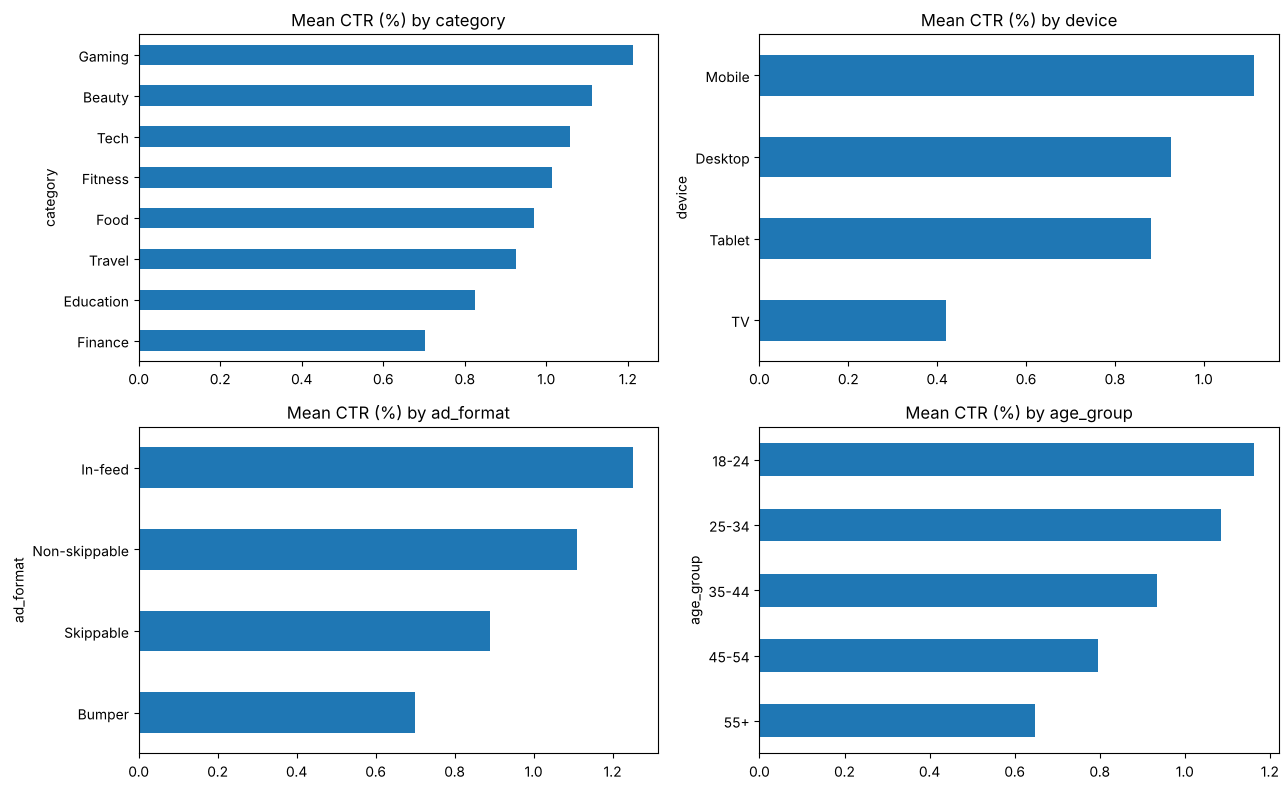

In [9]:
df['ctr'] = df['clicks'] / df['impressions']
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, ['category', 'device', 'ad_format', 'age_group']):
    (df.groupby(col)['ctr'].mean() * 100).sort_values().plot.barh(ax=ax)
    ax.set_title(f'Mean CTR (%) by {col}')
plt.tight_layout(); plt.show()

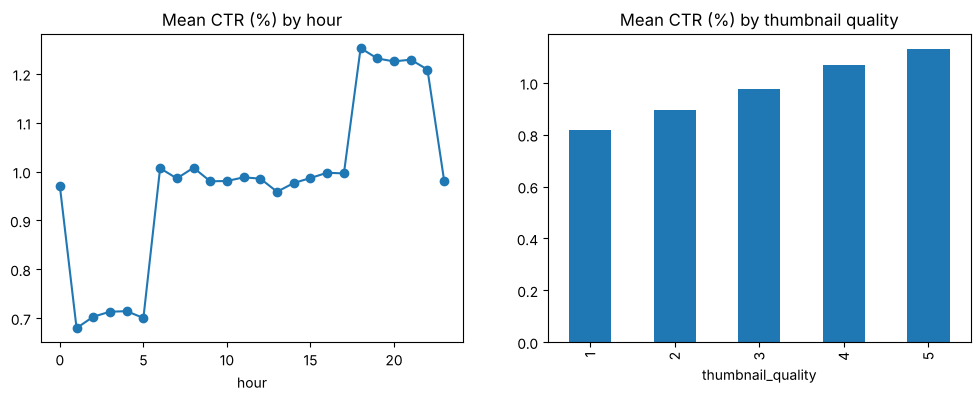

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(df.groupby('hour')['ctr'].mean() * 100).plot(ax=ax[0], marker='o'); ax[0].set_title('Mean CTR (%) by hour')
(df.groupby('thumbnail_quality')['ctr'].mean() * 100).plot.bar(ax=ax[1]); ax[1].set_title('Mean CTR (%) by thumbnail quality')
plt.show()

## 5. Feature engineering
- `log_impressions`, `log_budget`, `log_subscribers`: log transforms of skewed counts
- `time_of_day`: groups hours into night, morning, afternoon and evening
- Categories are one-hot encoded and numbers are scaled inside the model pipeline (see `src/features.py`)

In [11]:
df = add_features(df)
df['log_clicks'] = np.log1p(df['clicks'])
df[NUMERIC + ['clicks', 'log_clicks']].corr()[['clicks', 'log_clicks']].round(3).sort_values('log_clicks', ascending=False)

,clicks,log_clicks
log_clicks,0.779,1.000
log_impressions,0.689,0.846
log_budget,0.659,0.807
clicks,1.000,0.779
video_watch_pct,0.093,0.115
thumbnail_quality,0.081,0.110
is_weekend,0.031,0.043
ad_length_sec,0.018,0.035
log_subscribers,0.003,0.004


`log_impressions` and `log_budget` are strongly correlated with each other (budget buys impressions). That's called multicollinearity: it doesn't hurt predictions much, but it makes individual coefficients harder to interpret. We'll keep both for now and check the coefficients in Step 2.

## 6. Save the model-ready dataset

In [12]:
out = ROOT / 'data' / 'youtube_ads_clean.csv'
df[['ad_id'] + NUMERIC + CATEGORICAL + [TARGET]].to_csv(out, index=False)
print('Saved', out, df.shape)

Saved /mnt/attach/project-files/youtube-ads-pred/data/youtube_ads_clean.csv (20000, 21)


## Key takeaways
1. Impressions are by far the biggest driver of clicks; on a log scale the link is linear.
2. Device, ad format, category, audience age and time of day all shift the click-through rate.
3. Clicks are skewed, so predicting `log(1 + clicks)` will likely fit a linear model better.
4. `channel_subscribers` has almost zero correlation with clicks. Not every plausible feature is useful; Step 2 will confirm this from its coefficient.
5. `ad_length_sec` looks slightly positive only because 6-second bumper ads have a low CTR. This is why we look at features together in a model, not one at a time.

**Next (Step 2):** train the linear regression model and evaluate it.